# State-wise public health expenditure analysis
## India, 2023–24 and 2024–25 (Revised Estimates)

This notebook analyses RBI Statement 27: expenditure on Medical and Public Health and Family Welfare as a percentage of aggregate expenditure. The 2024–25 observations are Revised Estimates (RE), not audited actuals.

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

DATA_PATH = Path('../Dataset/state_health_expenditure_share_rbi_2024_25_re.csv')
df = pd.read_csv(DATA_PATH)
df.head()

,state_ut,health_expenditure_share_aggregate_2023_24_pct,health_expenditure_share_aggregate_2024_25_re_pct,estimate_type_2024_25
0,Andhra Pradesh,6.0,6.3,Revised Estimate
1,Arunachal Pradesh,5.7,5.2,Revised Estimate
2,Assam,5.6,6.0,Revised Estimate
3,Bihar,5.2,5.8,Revised Estimate
4,Chhattisgarh,4.5,6.5,Revised Estimate


## 1. Data validation


In [2]:
print('Observations:', len(df))
print('Missing values:\n', df.isna().sum())
assert len(df) == 31
assert df['state_ut'].is_unique
assert df['health_expenditure_share_aggregate_2024_25_re_pct'].between(0, 100).all()

Observations: 31
Missing values:
 state_ut                                             0
health_expenditure_share_aggregate_2023_24_pct       0
health_expenditure_share_aggregate_2024_25_re_pct    0
estimate_type_2024_25                                0
dtype: int64


## 2. 2024–25 RE: cross-state comparison

The chart ranks states and UTs by the share of aggregate expenditure allocated to Medical and Public Health and Family Welfare. This is a budget-composition measure, not an absolute spending measure.

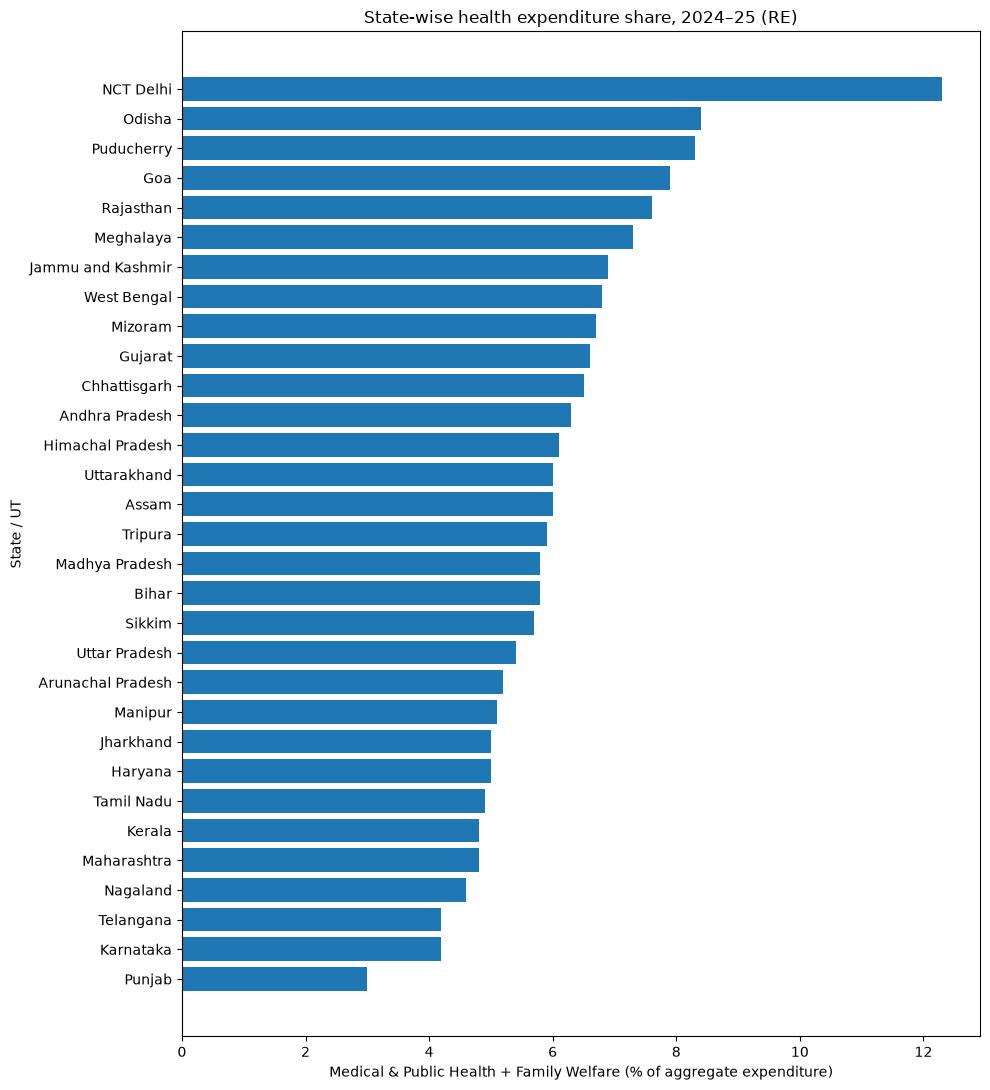

In [3]:
ranked = df.sort_values('health_expenditure_share_aggregate_2024_25_re_pct')
plt.figure(figsize=(10, 11))
plt.barh(ranked['state_ut'], ranked['health_expenditure_share_aggregate_2024_25_re_pct'])
plt.xlabel('Medical & Public Health + Family Welfare (% of aggregate expenditure)')
plt.ylabel('State / UT')
plt.title('State-wise health expenditure share, 2024–25 (RE)')
plt.tight_layout()
plt.show()

## 3. Change between 2023–24 and 2024–25 RE


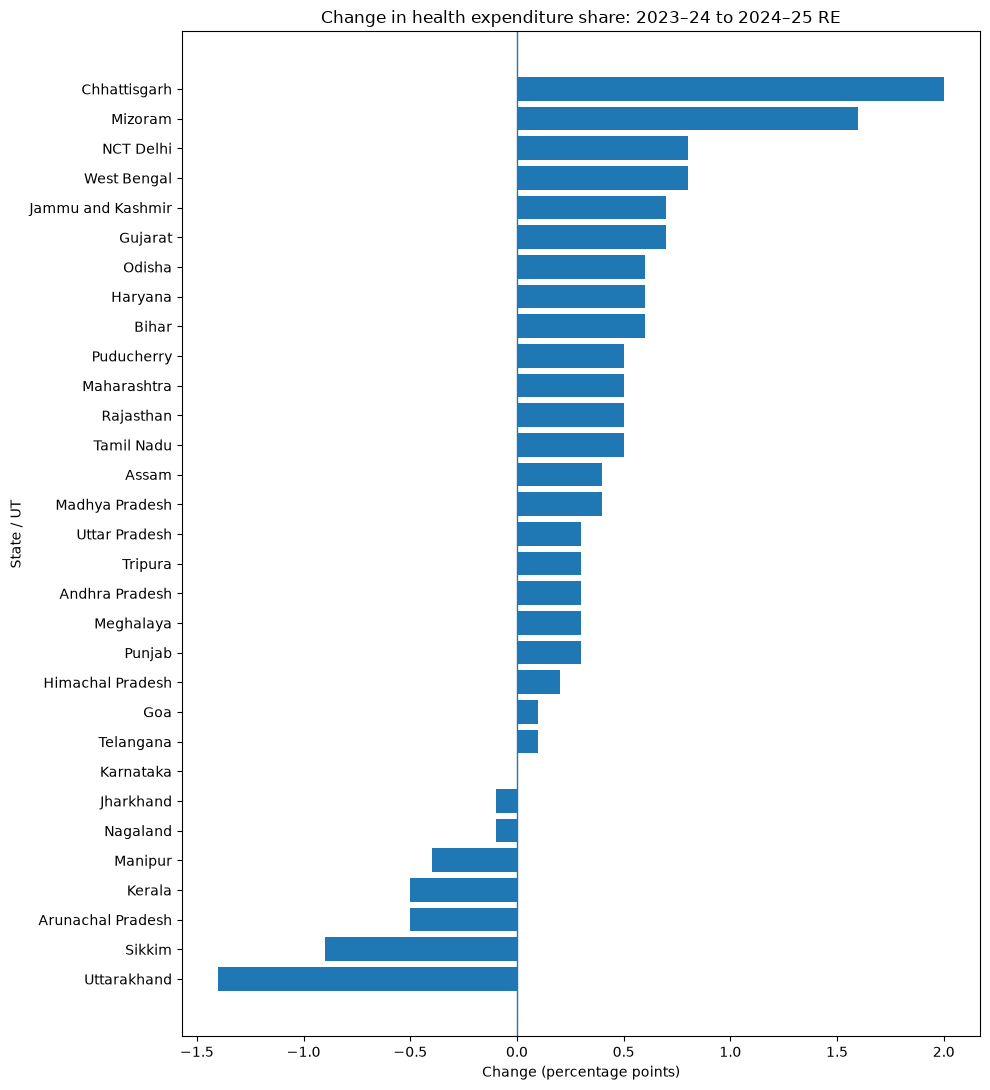

,state_ut,health_expenditure_share_aggregate_2023_24_pct,health_expenditure_share_aggregate_2024_25_re_pct,estimate_type_2024_25,change_percentage_points
4,Chhattisgarh,4.5,6.5,Revised Estimate,2.0
16,Mizoram,5.1,6.7,Revised Estimate,1.6
29,NCT Delhi,11.5,12.3,Revised Estimate,0.8
27,West Bengal,6.0,6.8,Revised Estimate,0.8
28,Jammu and Kashmir,6.2,6.9,Revised Estimate,0.7
6,Gujarat,5.9,6.6,Revised Estimate,0.7
18,Odisha,7.8,8.4,Revised Estimate,0.6
7,Haryana,4.4,5.0,Revised Estimate,0.6
3,Bihar,5.2,5.8,Revised Estimate,0.6
30,Puducherry,7.8,8.3,Revised Estimate,0.5


In [4]:
df['change_percentage_points'] = df['health_expenditure_share_aggregate_2024_25_re_pct'] - df['health_expenditure_share_aggregate_2023_24_pct']
change = df.sort_values('change_percentage_points')
plt.figure(figsize=(10, 11))
plt.barh(change['state_ut'], change['change_percentage_points'])
plt.axvline(0, linewidth=1)
plt.xlabel('Change (percentage points)')
plt.ylabel('State / UT')
plt.title('Change in health expenditure share: 2023–24 to 2024–25 RE')
plt.tight_layout()
plt.show()
df.sort_values('change_percentage_points', ascending=False).head(10)

## 4. Summary statistics


In [5]:
col = 'health_expenditure_share_aggregate_2024_25_re_pct'
print(df[col].describe())
print('\nHighest shares:')
display(df.nlargest(5, col)[['state_ut', col]])
print('\nLowest shares:')
display(df.nsmallest(5, col)[['state_ut', col]])

count    31.000000
mean      6.100000
std       1.697645
min       3.000000
25%       5.000000
50%       5.900000
75%       6.750000
max      12.300000
Name: health_expenditure_share_aggregate_2024_25_re_pct, dtype: float64

Highest shares:


,state_ut,health_expenditure_share_aggregate_2024_25_re_pct
29,NCT Delhi,12.3
18,Odisha,8.4
30,Puducherry,8.3
5,Goa,7.9
20,Rajasthan,7.6



Lowest shares:


,state_ut,health_expenditure_share_aggregate_2024_25_re_pct
19,Punjab,3.0
10,Karnataka,4.2
23,Telangana,4.2
17,Nagaland,4.6
11,Kerala,4.8


## 5. Interpretation cautions

- 2024–25 figures are Revised Estimates (RE).
- A higher percentage does not necessarily mean higher absolute spending or better health services.
- Differences may reflect fiscal capacity, spending priorities, and the size/composition of aggregate expenditure.
- This dataset alone cannot establish healthcare access, affordability, service quality, or causal effects on health outcomes.

## Source
Reserve Bank of India, *State Finances: A Study of Budgets of 2025–26*, Statement 27: https://www.rbi.org.in/scripts/PublicationsView.aspx?id=23736